# Standard CNN Architecture in Keras (Chapter 14)

This notebook breaks down a classic **Convolutional Neural Network (CNN)** architecture for `28 × 28` grayscale images (such as MNIST / Fashion-MNIST):

```python
Input [28, 28, 1]
  -> Conv2D(64, 7x7) -> MaxPool(2)                  # [14, 14, 64]
  -> Conv2D(128, 3x3) -> Conv2D(128, 3x3) -> MaxPool(2)  # [7, 7, 128]
  -> Conv2D(256, 3x3) -> Conv2D(256, 3x3) -> MaxPool(2)  # [3, 3, 256]
  -> Flatten()                                      # [2304]
  -> Dense(128) -> Dropout(0.5)
  -> Dense(64)  -> Dropout(0.5)
  -> Dense(10, softmax)
```

## 1. The Keras Model Definition

### Key Design Choices Explained:
1. **`partial()` Wrapper (`DefaultConv2D`):**
   * Pre-fills default arguments (`kernel_size=3`, `activation='relu'`, `padding='SAME'`) so we don't have to repeat them on every single convolutional layer.
2. **First Convolutional Layer (`filters=64, kernel_size=7, input_shape=[28, 28, 1]`):**
   * Uses a larger `7 × 7` kernel (the first-layer exception!), **without a stride (`stride=1`)** because `28 × 28` images are already quite small.
   * `input_shape=[28, 28, 1]` means `28 × 28` pixels with `1` color channel (grayscale).
3. **Repeating `[Conv -> Conv -> MaxPool]` Blocks:**
   * Each `MaxPooling2D(pool_size=2)` cuts the height and width in half ($\div 2$, reducing spatial area by $4\times$).
   * **Why filters double (`64 -> 128 -> 256`):** There are only a few low-level patterns (lines, simple edges), so `64` filters are enough early on. Higher layers combine those into many more complex shapes, so we need more filters. Because pooling just shrank the image size, **doubling the filters after each pooling layer** doesn't explode memory or parameters!
4. **Classifier Head (`Flatten -> Dense -> Dropout -> Softmax`):**
   * **`Flatten()`:** Dense layers expect a 1D vector per image, so we flatten the `[3, 3, 256]` 3D stack into a `2,304`-element 1D vector.
   * **`Dropout(0.5)`:** Randomly drops 50% of neurons during training to prevent overfitting in the dense layers.
   * **`Dense(10, activation='softmax')`:** Outputs probabilities across the 10 classes (`0–9`).

In [1]:
from functools import partial

try:
    from tensorflow import keras

    DefaultConv2D = partial(
        keras.layers.Conv2D,
        kernel_size=3,
        activation="relu",
        padding="SAME",
    )

    model = keras.models.Sequential([
        DefaultConv2D(filters=64, kernel_size=7, input_shape=[28, 28, 1]),
        keras.layers.MaxPooling2D(pool_size=2),
        DefaultConv2D(filters=128),
        DefaultConv2D(filters=128),
        keras.layers.MaxPooling2D(pool_size=2),
        DefaultConv2D(filters=256),
        DefaultConv2D(filters=256),
        keras.layers.MaxPooling2D(pool_size=2),
        keras.layers.Flatten(),
        keras.layers.Dense(units=128, activation="relu"),
        keras.layers.Dropout(0.5),
        keras.layers.Dense(units=64, activation="relu"),
        keras.layers.Dropout(0.5),
        keras.layers.Dense(units=10, activation="softmax"),
    ])
    model.summary()
except ImportError:
    print("TensorFlow/Keras is not installed in this venv — running exact layer-by-layer shape & parameter breakdown below!")

TensorFlow/Keras is not installed in this venv — running exact layer-by-layer shape & parameter breakdown below!


## 2. Layer-by-Layer Shape & Parameter Tracker
Let's trace how the `[28, 28, 1]` image shrinks in **Height × Width** while growing in **Depth (Feature Maps)** as it passes through every layer of this model, and count how many weights each layer has:
* **Conv2D Parameters Formula:** $(\text{kernel\_h} \times \text{kernel\_w} \times \text{in\_channels} + 1\text{ bias}) \times \text{filters}$
* **MaxPooling2D Parameters:** $0$ (no weights!)
* **Dense Parameters Formula:** $(\text{in\_units} + 1\text{ bias}) \times \text{out\_units}$

In [2]:
layers_spec = [
    ("Input",           (28, 28, 1),   0,                             "28x28 grayscale image"),
    ("Conv2D (7x7, 64)",(28, 28, 64),  (7 * 7 * 1 + 1) * 64,          "Large 7x7 kernel on 1-ch input"),
    ("MaxPool2D (2x2)", (14, 14, 64),  0,                             "Halves H & W (28 -> 14), 0 weights"),
    ("Conv2D (3x3, 128)",(14, 14, 128),(3 * 3 * 64 + 1) * 128,        "Doubles filters (64 -> 128)"),
    ("Conv2D (3x3, 128)",(14, 14, 128),(3 * 3 * 128 + 1) * 128,       "2nd 3x3 conv in block"),
    ("MaxPool2D (2x2)", (7, 7, 128),   0,                             "Halves H & W (14 -> 7), 0 weights"),
    ("Conv2D (3x3, 256)",(7, 7, 256),  (3 * 3 * 128 + 1) * 256,       "Doubles filters (128 -> 256)"),
    ("Conv2D (3x3, 256)",(7, 7, 256),  (3 * 3 * 256 + 1) * 256,       "2nd 3x3 conv in block"),
    ("MaxPool2D (2x2)", (3, 3, 256),   0,                             "Halves H & W (7 -> 3), 0 weights"),
    ("Flatten",         (2304,),       0,                             "3 * 3 * 256 = 2,304 1D features"),
    ("Dense (128)",     (128,),        (2304 + 1) * 128,              "Fully connected hidden layer 1"),
    ("Dropout (0.5)",   (128,),        0,                             "Drops 50% neurons during training"),
    ("Dense (64)",      (64,),         (128 + 1) * 64,                "Fully connected hidden layer 2"),
    ("Dropout (0.5)",   (64,),         0,                             "Drops 50% neurons during training"),
    ("Dense (10, Softmax)",(10,),      (64 + 1) * 10,                 "10 output class probabilities"),
]

print(f"{'Layer':<22} | {'Output Shape':<15} | {'Parameters':>12} | {'What Happens'}")
print("-" * 92)
total_params = 0
for name, shape, params, note in layers_spec:
    total_params += params
    print(f"{name:<22} | {str(shape):<15} | {params:>12,} | {note}")
print("-" * 92)
print(f"{'Total Trainable Parameters':<40} : {total_params:>12,}")

Layer                  | Output Shape    |   Parameters | What Happens
--------------------------------------------------------------------------------------------
Input                  | (28, 28, 1)     |            0 | 28x28 grayscale image
Conv2D (7x7, 64)       | (28, 28, 64)    |        3,200 | Large 7x7 kernel on 1-ch input
MaxPool2D (2x2)        | (14, 14, 64)    |            0 | Halves H & W (28 -> 14), 0 weights
Conv2D (3x3, 128)      | (14, 14, 128)   |       73,856 | Doubles filters (64 -> 128)
Conv2D (3x3, 128)      | (14, 14, 128)   |      147,584 | 2nd 3x3 conv in block
MaxPool2D (2x2)        | (7, 7, 128)     |            0 | Halves H & W (14 -> 7), 0 weights
Conv2D (3x3, 256)      | (7, 7, 256)     |      295,168 | Doubles filters (128 -> 256)
Conv2D (3x3, 256)      | (7, 7, 256)     |      590,080 | 2nd 3x3 conv in block
MaxPool2D (2x2)        | (3, 3, 256)     |            0 | Halves H & W (7 -> 3), 0 weights
Flatten                | (2304,)         |            0 | 

## 3. Visualizing the Shape Pyramid (`[28,28,1]` $\rightarrow$ `[3,3,256]`)
Notice the classic CNN trade-off as we move deeper into the network:
* **Spatial Size (`Height × Width`) shrinks:** `28×28` $\rightarrow$ `14×14` $\rightarrow$ `7×7` $\rightarrow$ `3×3`
* **Feature Channels (`Filters`) double:** `1` $\rightarrow$ `64` $\rightarrow$ `128` $\rightarrow$ `256`

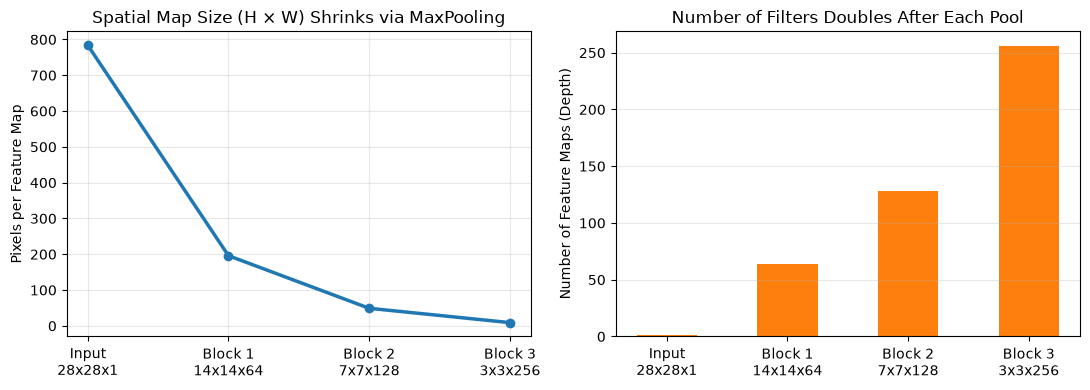

In [3]:
import matplotlib.pyplot as plt

stages = ["Input\n28x28x1", "Block 1\n14x14x64", "Block 2\n7x7x128", "Block 3\n3x3x256"]
spatial_pixels = [28 * 28, 14 * 14, 7 * 7, 3 * 3]
num_filters = [1, 64, 128, 256]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(stages, spatial_pixels, marker="o", linewidth=2.5, color="tab:blue")
axes[0].set_title("Spatial Map Size (H × W) Shrinks via MaxPooling")
axes[0].set_ylabel("Pixels per Feature Map")
axes[0].grid(True, alpha=0.3)

axes[1].bar(stages, num_filters, color="tab:orange", width=0.5)
axes[1].set_title("Number of Filters Doubles After Each Pool")
axes[1].set_ylabel("Number of Feature Maps (Depth)")
axes[1].grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()